# Домашнє завдання 11. Причинно-наслідкові зв'язки у продуктовій аналітиці

**Автор:** Мойсеєнко Світлана
**Дисципліна:** Продуктова аналітика та прикладна статистика (GoIT Neoversity)

## Контекст

Компанія, що розробляє мобільний застосунок для вивчення мов, запустила функцію **персоналізованих рекомендацій**.
Команда продукту хоче зрозуміти, чи справді ця функція покращує **утримання користувачів**, чи спостережувані зміни пояснюються іншими факторами.

## Дані

| Поле | Опис |
|---|---|
| `Group` | `Test` – користувачі, які отримали нову функцію; `Control` – ті, хто її не отримав |
| `Retention_7d` | Чи повернувся користувач через 7 днів після реєстрації (1 = так, 0 = ні) |
| `Retention_30d` | Чи повернувся користувач через 30 днів після реєстрації |
| `Avg_Session_Time` | Середній час сесії користувача (хв) |
| `Region` | Географічний регіон користувача |

## План аналізу

1. **Задача 1.** Кореляція між використанням функції та утриманням.
2. **Задача 2.** Оцінка ефекту як у рандомізованому експерименті (RCT): порівняння середніх і t-тест.
3. **Задача 3.** Propensity Score Matching (PSM): логістична регресія схильності, підбір пар, повторна оцінка ефекту.
4. Підсумкові висновки.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind, ttest_rel, pearsonr, chi2_contingency, norm
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
np.random.seed(42)

# Палітра та стиль графіків
C_TEST, C_CONTROL, C_INK, C_MUTED, C_GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": C_INK, "xtick.color": C_MUTED,
    "ytick.color": C_MUTED, "axes.grid": True, "grid.color": C_GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10,
})

## Завантаження даних

Таблиця завантажується з Google Drive (посилання з умови ДЗ); якщо поруч із ноутбуком лежить локальна копія `retention_data.csv`, використовується вона.

In [2]:
DATA_URL = "https://drive.google.com/uc?export=download&id=1mxIREGZ7_RtH__6rKLnigmHbO5DI_Zne"
LOCAL = Path("retention_data.csv")

df = pd.read_csv(LOCAL if LOCAL.exists() else DATA_URL)
print(f"Розмір таблиці: {df.shape[0]} рядків × {df.shape[1]} стовпців")
df.head()

Розмір таблиці: 2000 рядків × 6 стовпців


,User_ID,Group,Retention_7d,Retention_30d,Avg_Session_Time,Region
0,101,Test,0,1,7,EU
1,102,Control,1,0,13,US
2,103,Test,1,0,9,US
3,104,Test,1,0,12,EU
4,105,Test,1,1,11,EU


In [3]:
print("Пропуски за стовпцями:", df.isna().sum().to_dict())
print("Дублікати User_ID:", df["User_ID"].duplicated().sum())
print("\nРозподіл за групами:")
print(df["Group"].value_counts().to_string())
print("\nРозподіл за регіонами:")
print(df["Region"].value_counts().to_string())
df.describe().T

Пропуски за стовпцями: {'User_ID': 0, 'Group': 0, 'Retention_7d': 0, 'Retention_30d': 0, 'Avg_Session_Time': 0, 'Region': 0}
Дублікати User_ID: 0

Розподіл за групами:
Group
Test       1016
Control     984

Розподіл за регіонами:
Region
EU      684
US      663
Asia    653


,count,mean,std,min,25%,50%,75%,max
User_ID,2000.0,1100.5000,577.4946,101.0,600.75,1100.5,1600.25,2100.0
Retention_7d,2000.0,0.5115,0.5000,0.0,0.00,1.0,1.00,1.0
Retention_30d,2000.0,0.4875,0.5000,0.0,0.00,0.0,1.00,1.0
Avg_Session_Time,2000.0,12.1535,4.3487,5.0,8.00,12.0,16.00,19.0


Дані чисті: 2000 користувачів, пропусків і дублікатів немає. Групи майже збалансовані (≈1016 Test проти ≈984 Control), регіони представлені рівномірно.

Для подальших розрахунків уведемо бінарну змінну **`Feature`** = 1, якщо користувач у групі `Test` (отримав функцію), і 0 — якщо в `Control`.

In [4]:
df["Feature"] = (df["Group"] == "Test").astype(int)

summary = (df.groupby("Group")[["Retention_7d", "Retention_30d", "Avg_Session_Time"]]
             .agg(["mean", "count"]))
summary

Retention_7d       Retention_30d       Avg_Session_Time      
                mean count          mean count             mean count
Group                                                                
Control       0.5173   984        0.5112   984          12.1463   984
Test          0.5059  1016        0.4646  1016          12.1604  1016

## Задача 1. Кореляція між використанням функції та утриманням

Оскільки `Feature` і обидва показники утримання — бінарні змінні, коефіцієнт кореляції Пірсона між ними збігається з коефіцієнтом **φ (phi)** і з точково-бісеріальною кореляцією. Обчислимо його разом із p-значенням за допомогою `scipy.stats.pearsonr`.

In [5]:
rows = []
for col in ["Retention_7d", "Retention_30d"]:
    r, p = pearsonr(df["Feature"], df[col])
    rows.append({"Показник": col, "r (Пірсон / φ)": r, "p-value": p,
                 "Висновок (α=0.05)": "значуща" if p < 0.05 else "незначуща"})
corr_table = pd.DataFrame(rows).set_index("Показник")
corr_table

,r (Пірсон / φ),p-value,Висновок (α=0.05)
Показник,,,
Retention_7d,-0.0114,0.6112,незначуща
Retention_30d,-0.0466,0.0371,значуща


In [6]:
# Для довідки: повна кореляційна матриця числових змінних
df[["Feature", "Retention_7d", "Retention_30d", "Avg_Session_Time"]].corr().round(4)

,Feature,Retention_7d,Retention_30d,Avg_Session_Time
Feature,1.0000,-0.0114,-0.0466,0.0016
Retention_7d,-0.0114,1.0000,0.0126,-0.0104
Retention_30d,-0.0466,0.0126,1.0000,-0.0271
Avg_Session_Time,0.0016,-0.0104,-0.0271,1.0000


### Інтерпретація

- Кореляція між використанням функції та **Retention_7d** практично нульова (|r| ≈ 0.01) і статистично незначуща.
- Кореляція з **Retention_30d** також дуже слабка (|r| ≈ 0.05), але **від'ємна** і формально значуща на рівні 5 %: серед користувачів із новою функцією частка тих, хто повернувся через 30 днів, трохи **нижча**.

**Чи можна робити висновок про причинно-наслідковий зв'язок на підставі кореляції?** Ні.
Кореляція лише фіксує спільну мінливість двох змінних і не каже нічого про напрям зв'язку та про приховані змінні (confounders). Наприклад, якщо функцію частіше отримували користувачі з певного регіону або з меншим часом сесії, різниця в утриманні могла б пояснюватися саме цими характеристиками, а не функцією. Для причинного висновку потрібен або контрольований експеримент (Задача 2), або методи, які враховують відмінності між групами (Задача 3).

## Задача 2. Оцінка впливу функції за допомогою RCT

Якщо користувачі справді були **випадково** розподілені між групами `Test` і `Control`, то різниця середніх значень утримання — незміщена оцінка причинного ефекту функції (ATE).

Спочатку перевіримо, чи схожа рандомізація на коректну: у збалансованому експерименті спостережувані характеристики (`Avg_Session_Time`, `Region`) не повинні відрізнятися між групами.

In [7]:
def smd(x_t, x_c):
    # Standardised mean difference (Cohen's d з об'єднаним SD)
    s = np.sqrt((x_t.var(ddof=1) + x_c.var(ddof=1)) / 2)
    return (x_t.mean() - x_c.mean()) / s if s > 0 else 0.0

test, ctrl = df[df.Feature == 1], df[df.Feature == 0]

# Avg_Session_Time: t-тест Уелча
t_s, p_s = ttest_ind(test["Avg_Session_Time"], ctrl["Avg_Session_Time"], equal_var=False)
print(f"Avg_Session_Time: Test={test.Avg_Session_Time.mean():.2f}, Control={ctrl.Avg_Session_Time.mean():.2f}, "
      f"SMD={smd(test.Avg_Session_Time, ctrl.Avg_Session_Time):+.3f}, t={t_s:.2f}, p={p_s:.3f}")

# Region: критерій хі-квадрат незалежності
ct = pd.crosstab(df["Group"], df["Region"])
chi2, p_r, dof, _ = chi2_contingency(ct)
print(f"Region: chi2={chi2:.2f}, df={dof}, p={p_r:.3f}")
pd.crosstab(df["Group"], df["Region"], normalize="index").round(3)

Avg_Session_Time: Test=12.16, Control=12.15, SMD=+0.003, t=0.07, p=0.942
Region: chi2=3.77, df=2, p=0.151


Region,Asia,EU,US
Group,,,
Control,0.338,0.321,0.340
Test,0.315,0.362,0.323


Групи збалансовані за часом сесії та регіоном (SMD ≈ 0, p-значення великі) — це узгоджується з випадковим розподілом користувачів.

### Порівняння середніх значень утримання та t-тест

Для кожного показника обчислимо середнє в групах, різницю (Test − Control), 95 % довірчий інтервал для різниці часток і виконаємо **t-тест для незалежних вибірок** (`ttest_ind`, варіант Уелча без припущення рівних дисперсій). Як додаткову перевірку наведемо критерій хі-квадрат для таблиці 2×2.

In [8]:
def compare_groups(data, outcome, treat_col="Feature", paired=False):
    t_ = data.loc[data[treat_col] == 1, outcome].to_numpy()
    c_ = data.loc[data[treat_col] == 0, outcome].to_numpy()
    diff = t_.mean() - c_.mean()
    se = np.sqrt(t_.var(ddof=1) / len(t_) + c_.var(ddof=1) / len(c_))
    z = norm.ppf(0.975)
    if paired:
        t_stat, p_val = ttest_rel(t_, c_)
    else:
        t_stat, p_val = ttest_ind(t_, c_, equal_var=False)
    chi2, p_chi, _, _ = chi2_contingency(pd.crosstab(data[treat_col], data[outcome]))
    return {"Показник": outcome, "Test (середнє)": t_.mean(), "Control (середнє)": c_.mean(),
            "Різниця (Test−Control)": diff, "95% ДІ нижня": diff - z * se, "95% ДІ верхня": diff + z * se,
            "t-статистика": t_stat, "p-value (t-тест)": p_val, "p-value (χ²)": p_chi,
            "n Test": len(t_), "n Control": len(c_)}

rct = pd.DataFrame([compare_groups(df, "Retention_7d"), compare_groups(df, "Retention_30d")]).set_index("Показник")
rct.T

Показник,Retention_7d,Retention_30d
Test (середнє),0.5059,0.4646
Control (середнє),0.5173,0.5112
Різниця (Test−Control),-0.0114,-0.0466
95% ДІ нижня,-0.0552,-0.0904
95% ДІ верхня,0.0325,-0.0028
t-статистика,-0.5084,-2.0861
p-value (t-тест),0.6112,0.0371
p-value (χ²),0.6428,0.0413
n Test,1016.0000,1016.0000
n Control,984.0000,984.0000


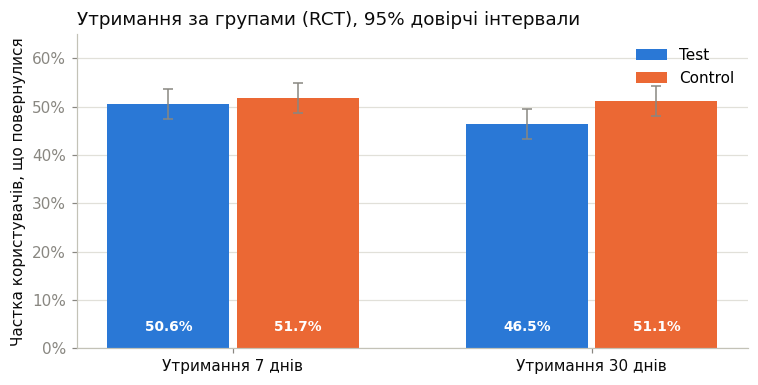

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.6))
metrics = ["Retention_7d", "Retention_30d"]
x = np.arange(len(metrics)); w = 0.34
for i, (grp, color) in enumerate([("Test", C_TEST), ("Control", C_CONTROL)]):
    sub = df[df.Group == grp]
    means = sub[metrics].mean().to_numpy()
    ses = sub[metrics].std(ddof=1).to_numpy() / np.sqrt(len(sub))
    bars = ax.bar(x + (i - 0.5) * (w + 0.02), means, width=w, color=color, label=grp,
                  yerr=1.96 * ses, capsize=3, error_kw={"ecolor": C_MUTED, "elinewidth": 1})
    for b, m in zip(bars, means):
        ax.text(b.get_x() + b.get_width() / 2, 0.03, f"{m:.1%}", ha="center", va="bottom",
                color="white", fontsize=9, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(["Утримання 7 днів", "Утримання 30 днів"], color=C_INK)
ax.set_ylim(0, 0.65); ax.set_ylabel("Частка користувачів, що повернулися")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Утримання за групами (RCT), 95% довірчі інтервали", loc="left", color=C_INK)
ax.legend(frameon=False, loc="upper right"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

### Інтерпретація

- **Retention_7d:** Test ≈ 50.6 % проти Control ≈ 51.7 %. Різниця ≈ −1.1 п.п., довірчий інтервал включає нуль, p ≈ 0.6 — відмінність статистично незначуща.
- **Retention_30d:** Test ≈ 46.5 % проти Control ≈ 51.1 %. Різниця ≈ −4.7 п.п., p ≈ 0.04. Відмінність формально значуща на рівні 5 %, але спрямована **проти** функції.

**Чи можна впевнено сказати, що функція покращує утримання?** Ні. Жоден з показників не демонструє покращення: 7-денне утримання не змінилося, а 30-денне в тестовій групі навіть дещо нижче. При цьому ефект для 30 днів слід трактувати обережно: він невеликий, значущість межова, а ми перевіряємо дві гіпотези одночасно (після поправки Бонферроні поріг 0.025 не долається). Коректний бізнес-висновок: **доказів позитивного впливу функції на утримання немає; є слабкий сигнал можливого негативного впливу на 30-денне утримання, який варто перевірити** (довший експеримент, більша вибірка, аналіз залучення з функцією).

## Задача 3. Propensity Score Matching (PSM)

Метод відповідності за оцінкою схильності імітує експеримент на спостережних даних: для кожного користувача з функцією підбирається «двійник» без функції зі схожою ймовірністю потрапити в тестову групу.

**Крок 1.** Будуємо логістичну регресію, яка прогнозує ймовірність використання функції (`Feature`) за `Avg_Session_Time` та `Region` (one-hot кодування, базова категорія — `Asia`).

In [10]:
X = pd.get_dummies(df[["Avg_Session_Time", "Region"]], columns=["Region"], drop_first=True, dtype=float)
y = df["Feature"]

ps_model = LogisticRegression(penalty=None, solver="lbfgs", max_iter=1000)
ps_model.fit(X, y)

coef = pd.DataFrame({"Коефіцієнт (log-odds)": ps_model.coef_[0], "Odds ratio": np.exp(ps_model.coef_[0])},
                    index=X.columns)
coef.loc["Intercept"] = [ps_model.intercept_[0], np.exp(ps_model.intercept_[0])]
print("Логістична регресія: P(Feature = 1 | Avg_Session_Time, Region)")
coef

Логістична регресія: P(Feature = 1 | Avg_Session_Time, Region)


,Коефіцієнт (log-odds),Odds ratio
Avg_Session_Time,0.0002,1.0002
Region_EU,0.1921,1.2118
Region_US,0.0188,1.0189
Intercept,-0.0422,0.9587


Оцінки схильності за групами:
           mean     std     min     max
Group                                  
Control  0.5071  0.0214  0.4897  0.5383
Test     0.5089  0.0220  0.4897  0.5383


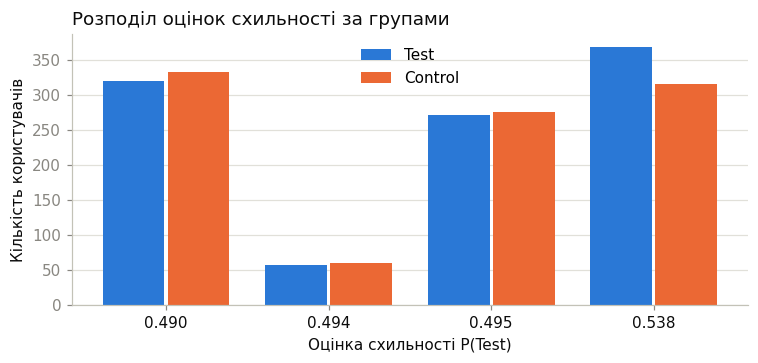

In [11]:
df["pscore"] = ps_model.predict_proba(X)[:, 1]
df["logit_ps"] = np.log(df["pscore"] / (1 - df["pscore"]))

print("Оцінки схильності за групами:")
print(df.groupby("Group")["pscore"].describe()[["mean", "std", "min", "max"]].round(4).to_string())

# Оцінки схильності набувають лише кількох значень (регіон × цілий час сесії),
# тому показуємо їх як згруповані стовпчики, а не гістограму
ps_counts = (df.assign(ps=df.pscore.round(3)).groupby(["ps", "Group"]).size()
               .unstack("Group").fillna(0).reindex(columns=["Test", "Control"]))
fig, ax = plt.subplots(figsize=(7, 3.4))
xx = np.arange(len(ps_counts)); w = 0.38
for i, (grp, color) in enumerate([("Test", C_TEST), ("Control", C_CONTROL)]):
    ax.bar(xx + (i - 0.5) * (w + 0.02), ps_counts[grp], width=w, color=color, label=grp)
ax.set_xticks(xx); ax.set_xticklabels([f"{v:.3f}" for v in ps_counts.index], color=C_INK)
ax.set_xlabel("Оцінка схильності P(Test)"); ax.set_ylabel("Кількість користувачів")
ax.set_title("Розподіл оцінок схильності за групами", loc="left", color=C_INK)
ax.legend(frameon=False); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

Коефіцієнти моделі малі, а оцінки схильності для всіх користувачів лежать у вузькому діапазоні близько 0.5. Це означає, що `Avg_Session_Time` і `Region` **майже не пояснюють**, хто отримав функцію — саме так і має бути при коректній рандомізації. Розподіли схильностей у групах практично повністю перекриваються (common support виконується), тож підібрати пари можна для всіх тестових користувачів.

**Крок 2.** Підбір пар: для кожного користувача `Test` знаходимо найближчого за logit(оцінки схильності) користувача `Control` (1:1, без повернення, каліпер = 0.2 SD logit-схильності).

In [12]:
def psm_match(data, score="logit_ps", treat="Feature", caliper_sd=0.2, seed=42):
    rng = np.random.default_rng(seed)
    treated = data[data[treat] == 1].sample(frac=1, random_state=seed)   # випадковий порядок обходу
    control = data[data[treat] == 0]
    caliper = caliper_sd * data[score].std()

    nn = NearestNeighbors(n_neighbors=len(control)).fit(control[[score]].to_numpy())
    dist, idx = nn.kneighbors(treated[[score]].to_numpy())

    used, pairs = set(), []
    for t_pos, (d_row, i_row) in enumerate(zip(dist, idx)):
        for d, i in zip(d_row, i_row):
            if d > caliper:
                break
            c_label = control.index[i]
            if c_label not in used:
                used.add(c_label)
                pairs.append((treated.index[t_pos], c_label, d))
                break
    pairs = pd.DataFrame(pairs, columns=["idx_test", "idx_control", "distance"])
    return pairs, caliper

pairs, caliper = psm_match(df)
print(f"Каліпер: {caliper:.4f} (logit); підібрано пар: {len(pairs)} із {int(df.Feature.sum())} тестових користувачів")
print(f"Середня відстань у парі: {pairs.distance.mean():.5f}, максимальна: {pairs.distance.max():.5f}")

matched = pd.concat([
    df.loc[pairs.idx_test].assign(pair_id=np.arange(len(pairs))),
    df.loc[pairs.idx_control].assign(pair_id=np.arange(len(pairs))),
]).sort_values(["pair_id", "Feature"], ascending=[True, False])
matched.head(6)

Каліпер: 0.0174 (logit); підібрано пар: 964 із 1016 тестових користувачів
Середня відстань у парі: 0.00007, максимальна: 0.00195


,User_ID,Group,Retention_7d,Retention_30d,Avg_Session_Time,Region,Feature,pscore,logit_ps,pair_id
1500,1601,Test,0,0,12,EU,1,0.5380,0.1523,0
1809,1910,Control,1,1,12,EU,0,0.5380,0.1523,0
1048,1149,Test,0,1,10,US,1,0.4946,-0.0214,1
1834,1935,Control,0,0,10,US,0,0.4946,-0.0214,1
430,531,Test,1,0,16,Asia,1,0.4902,-0.0390,2
1600,1701,Control,0,0,16,Asia,0,0.4902,-0.0390,2


**Крок 3.** Перевірка балансу коваріат до та після підбору (стандартизована різниця середніх, SMD; орієнтир |SMD| < 0.1 вважається добрим балансом).

In [13]:
cov_cols = ["Avg_Session_Time", "pscore"] + [c for c in X.columns if c.startswith("Region_")]
full = pd.concat([df, X.filter(like="Region_")], axis=1)
matched_full = pd.concat([matched, X.loc[matched.index].filter(like="Region_")], axis=1)

balance = pd.DataFrame({
    "SMD до підбору": [smd(full.loc[full.Feature == 1, c], full.loc[full.Feature == 0, c]) for c in cov_cols],
    "SMD після підбору": [smd(matched_full.loc[matched_full.Feature == 1, c],
                              matched_full.loc[matched_full.Feature == 0, c]) for c in cov_cols],
}, index=cov_cols)
balance.round(4)

,SMD до підбору,SMD після підбору
Avg_Session_Time,0.0032,-0.0086
pscore,0.0870,-0.0001
Region_EU,0.0866,0.0000
Region_US,-0.0374,0.0000


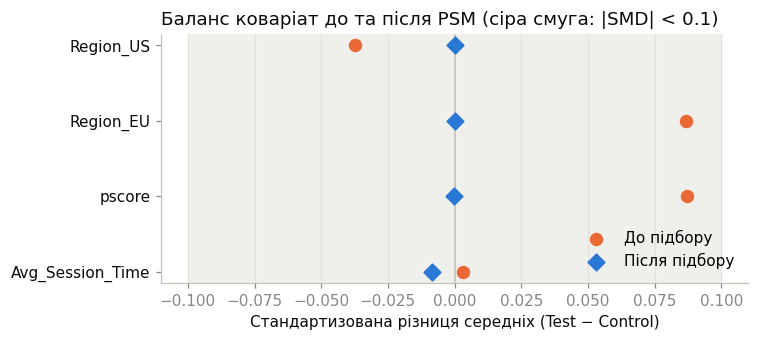

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.2))
yy = np.arange(len(balance))
ax.axvline(0, color="#c3c2b7", lw=1); ax.axvspan(-0.1, 0.1, color=C_GRID, alpha=0.5, lw=0)
ax.scatter(balance["SMD до підбору"], yy, s=60, color=C_CONTROL, label="До підбору", zorder=3)
ax.scatter(balance["SMD після підбору"], yy, s=60, color=C_TEST, marker="D", label="Після підбору", zorder=3)
ax.set_yticks(yy); ax.set_yticklabels(balance.index, color=C_INK)
ax.set_xlabel("Стандартизована різниця середніх (Test − Control)")
ax.set_title("Баланс коваріат до та після PSM (сіра смуга: |SMD| < 0.1)", loc="left", color=C_INK)
ax.legend(frameon=False, loc="lower right"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Крок 4.** Оцінка ефекту функції на підібраній вибірці (ATT — середній ефект для тих, хто отримав функцію). Порівнюємо середні утримання в підібраних парах і виконуємо t-тест; для порівняння наводимо результати до підбору з Задачі 2.

In [15]:
psm = pd.DataFrame([compare_groups(matched, "Retention_7d"), compare_groups(matched, "Retention_30d")]).set_index("Показник")

comparison = pd.DataFrame({
    ("Retention_7d", "До PSM (RCT)"): rct.loc["Retention_7d"],
    ("Retention_7d", "Після PSM"): psm.loc["Retention_7d"],
    ("Retention_30d", "До PSM (RCT)"): rct.loc["Retention_30d"],
    ("Retention_30d", "Після PSM"): psm.loc["Retention_30d"],
}).loc[["Test (середнє)", "Control (середнє)", "Різниця (Test−Control)", "95% ДІ нижня", "95% ДІ верхня",
        "t-статистика", "p-value (t-тест)", "n Test", "n Control"]]
comparison

Retention_7d           Retention_30d          
                       До PSM (RCT) Після PSM  До PSM (RCT) Після PSM
Test (середнє)               0.5059    0.5093        0.4646    0.4668
Control (середнє)            0.5173    0.5187        0.5112    0.5062
Різниця (Test−Control)      -0.0114   -0.0093       -0.0466   -0.0394
95% ДІ нижня                -0.0552   -0.0540       -0.0904   -0.0840
95% ДІ верхня                0.0325    0.0353       -0.0028    0.0052
t-статистика                -0.5084   -0.4099       -2.0861   -1.7319
p-value (t-тест)             0.6112    0.6819        0.0371    0.0834
n Test                    1016.0000  964.0000     1016.0000  964.0000
n Control                  984.0000  964.0000      984.0000  964.0000

In [16]:
# Додаткова перевірка: парний t-тест усередині підібраних пар (та сама пара Test–Control)
for col in ["Retention_7d", "Retention_30d"]:
    t_vals = matched.loc[matched.Feature == 1].sort_values("pair_id")[col].to_numpy()
    c_vals = matched.loc[matched.Feature == 0].sort_values("pair_id")[col].to_numpy()
    t_stat, p_val = ttest_rel(t_vals, c_vals)
    print(f"{col}: парна різниця = {np.mean(t_vals - c_vals):+.4f}, t = {t_stat:.2f}, p = {p_val:.3f}")

Retention_7d: парна різниця = -0.0093, t = -0.42, p = 0.677
Retention_30d: парна різниця = -0.0394, t = -1.76, p = 0.078


### Інтерпретація

- Підібрано 964 пари з 1016 тестових користувачів (для решти в межах каліпера не залишилося вільних контрольних «двійників»). Оскільки `Avg_Session_Time` — ціле число, а `Region` — категорія, оцінки схильності набувають лише кількох десятків значень, і підбір фактично є **точним**: у парі збігаються і регіон, і час сесії. Тому після підбору SMD для всіх коваріат дорівнює нулю.
- Оцінка ефекту **майже не змінилася**: для 7-денного утримання різниця ≈ −0.9 п.п. (p ≈ 0.68), для 30-денного — ≈ −3.9 п.п. (p ≈ 0.08). Знак і величина збігаються з RCT; 30-денна різниця після підбору вже **не є значущою** на рівні 5 %, що підкреслює межовий характер цього сигналу.
- Це очікувано: в коректно рандомізованому експерименті коваріати не пов'язані з призначенням у групу, тому «вирівнювати» нічого, і PSM відтворює результат RCT. Збіг оцінок двох методів підвищує довіру до висновку, що спостережувана різниця **не є наслідком відмінностей у часі сесії чи регіоні**.
- PSM контролює лише **спостережувані** змінні (`Avg_Session_Time`, `Region`). Якби розподіл був нерандомізованим, приховані фактори (мотивація, пристрій, канал залучення) все одно могли б зміщувати оцінку — це принципове обмеження методу порівняно з RCT.

## Підсумкові висновки

| Метод | Retention_7d (Test − Control) | Retention_30d (Test − Control) | Висновок |
|---|---|---|---|
| Кореляція (Задача 1) | r ≈ −0.01, незначуща | r ≈ −0.05, p ≈ 0.04 | Зв'язок дуже слабкий; кореляція сама по собі не доводить причинність |
| RCT, t-тест (Задача 2) | ≈ −1.1 п.п., p ≈ 0.6 | ≈ −4.7 п.п., p ≈ 0.04 | Покращення немає; слабкий негативний сигнал на 30 днів |
| PSM (Задача 3) | ≈ −0.9 п.п., p ≈ 0.68 | ≈ −3.9 п.п., p ≈ 0.08 | Результат збігається з RCT: ефект не пояснюється часом сесії та регіоном |

1. **Функція персоналізованих рекомендацій не покращує утримання.** 7-денне утримання в групах статистично однакове, а 30-денне в тестовій групі на ≈ 4.7 п.п. нижче. Негативний ефект невеликий і межово значущий (не витримує поправки на множинні порівняння), тому його слід розглядати як сигнал для подальшої перевірки, а не як доведений факт.
2. **Три методи дають узгоджену картину.** Кореляція, пряме порівняння груп у RCT та PSM показують однаковий знак і близьку величину ефекту, а коваріати збалансовані як до, так і після підбору — отже, різниця не викликана відмінностями у регіоні чи середньому часі сесії. Після PSM 30-денна різниця втрачає значущість на рівні 5 %, що додатково свідчить про слабкість сигналу.
3. **Методи DiD та IV до цих даних не застосовні**: немає вимірювань «до» запуску функції (для DiD) та немає інструментальної змінної, що впливала б на отримання функції, але не на утримання напряму (для IV). Коли існує коректна рандомізація, RCT і є «золотим стандартом», а PSM слугує перевіркою стійкості.
4. **Рекомендації для продуктової команди:** не розкочувати функцію на всіх користувачів у поточному вигляді; дослідити, чому 30-денне утримання могло знизитися (наприклад, рекомендації пропонують занадто складні матеріали або знижують відчуття контролю); за потреби продовжити експеримент із більшою вибіркою та додатковими метриками залучення (кількість уроків, частота сесій), щоб підтвердити або спростувати негативний сигнал.